In [3]:
# setup: load the data and the libraries for modelling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/german_credit.csv")
target = "Creditability"
print(df.shape)

(1000, 21)


In [5]:
# split into features (X) and target (y), then a stratified 70/30 train/test split
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Share of good in train:", round(y_train.mean(), 3))
print("Share of good in test:", round(y_test.mean(), 3))

Train: (700, 20)  Test: (300, 20)
Share of good in train: 0.7
Share of good in test: 0.7


## Train/test split

- Stratified 70/30 split (random_state = 42): 700 training and 300 test customers.
- Both sets keep the 70% good / 30% bad mix, so the test set looks like real life and all models are graded fairly.
- 70/30 rather than 80/20: with only 300 bad customers in total, the test set keeps 90 bad customers (vs 60), giving a more reliable FP rate.

In [7]:
# grade a model on the test set; fp_cost = cost of approving a bad customer (default 5)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

def evaluate(model, X_test, y_test, fp_cost=5):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"accuracy": round(accuracy_score(y_test, pred), 3),
            "TP rate": round(tp / (tp + fn), 3),
            "FP rate": round(fp / (fp + tn), 3),
            "AUC": round(roc_auc_score(y_test, prob), 3),
            "cost": fp_cost * fp + 1 * fn,
            "TP": tp, "FN": fn, "FP": fp, "TN": tn}

In [8]:
# Decision Tree on all 20 features, limited to 4 levels to avoid overfitting
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)
evaluate(tree, X_test, y_test)

{'accuracy': 0.733,
 'TP rate': np.float64(0.9),
 'FP rate': np.float64(0.656),
 'AUC': 0.723,
 'cost': np.int64(316),
 'TP': np.int64(189),
 'FN': np.int64(21),
 'FP': np.int64(59),
 'TN': np.int64(31)}

In [10]:
# choose the tree depth with 5-fold cross-validation on the TRAINING data only (scored by AUC)
from sklearn.model_selection import cross_val_score

for depth in [2, 3, 4, 5, 6, 8, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc")
    print(f"max_depth={depth}: mean AUC = {scores.mean():.3f} (+/- {scores.std():.3f})")

max_depth=2: mean AUC = 0.676 (+/- 0.033)
max_depth=3: mean AUC = 0.699 (+/- 0.042)
max_depth=4: mean AUC = 0.693 (+/- 0.018)
max_depth=5: mean AUC = 0.699 (+/- 0.023)
max_depth=6: mean AUC = 0.681 (+/- 0.010)
max_depth=8: mean AUC = 0.619 (+/- 0.063)
max_depth=None: mean AUC = 0.611 (+/- 0.025)


In [12]:
# final Decision Tree: depth 3, chosen by cross-validation (best mean AUC, simplest tree), graded once on the test set
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
evaluate(tree, X_test, y_test)

{'accuracy': 0.717,
 'TP rate': np.float64(0.886),
 'FP rate': np.float64(0.678),
 'AUC': 0.714,
 'cost': np.int64(329),
 'TP': np.int64(186),
 'FN': np.int64(24),
 'FP': np.int64(61),
 'TN': np.int64(29)}

In [13]:
# final Decision Tree: depth 3, chosen by cross-validation (best mean AUC, simplest tree), graded once on the test set
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
evaluate(tree, X_test, y_test)

{'accuracy': 0.717,
 'TP rate': np.float64(0.886),
 'FP rate': np.float64(0.678),
 'AUC': 0.714,
 'cost': np.int64(329),
 'TP': np.int64(186),
 'FN': np.int64(24),
 'FP': np.int64(61),
 'TN': np.int64(29)}

## Decision Tree (all 20 features, depth 3): test results

| Accuracy | TP rate | FP rate | AUC | Cost |
|---|---|---|---|---|
| 0.717 | 0.886 | 0.678 | 0.714 | 329 |

- Confusion matrix: 186 good approved, 24 good rejected, 61 bad approved, 29 bad rejected.
- Test AUC (0.714) is close to the cross-validation AUC (0.699), so the model generalizes as expected.
- With the default 0.5 cutoff the tree approves 68% of bad customers: the class imbalance pushes it toward "good". Balancing and a cost-based cutoff will address this.

KeyboardInterrupt: 

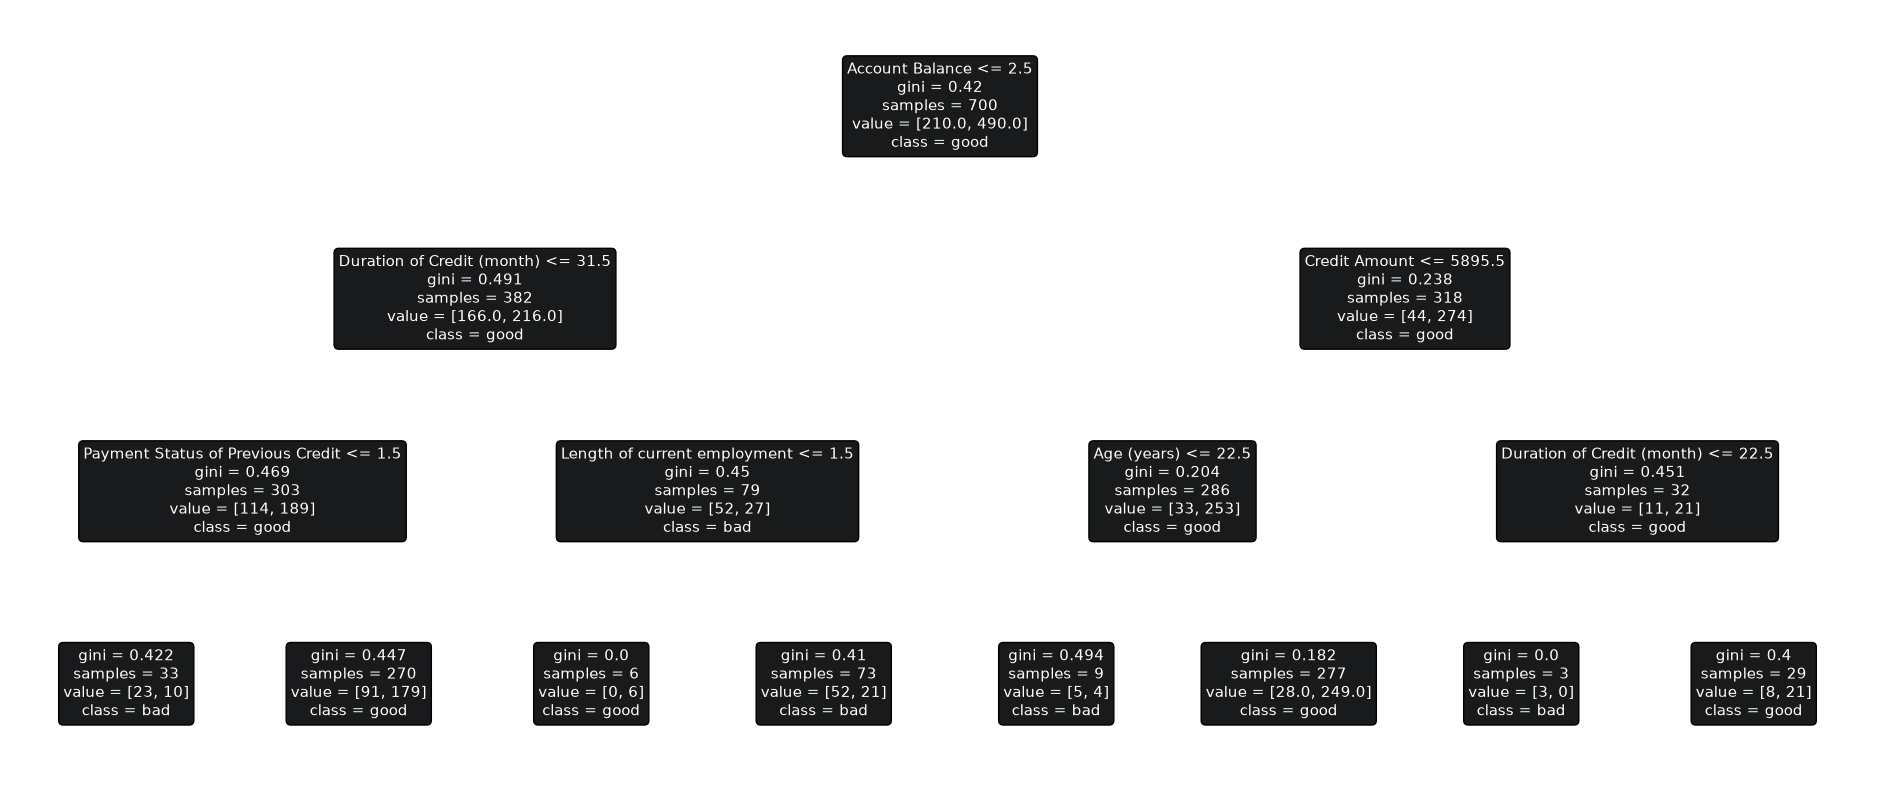

In [15]:
# draw the tree with clear colours: green = predicts good, red = predicts bad
from sklearn.tree import plot_tree
fig = plt.figure(figsize=(24, 10), facecolor="white")
boxes = plot_tree(tree, feature_names=X.columns, class_names=["bad", "good"],
                  filled=False, rounded=True, fontsize=11)
for box in boxes:
    bbox = box.get_bbox_patch()
    if bbox is not None:
        bbox.set_facecolor("#c8e6c9" if "class = good" in box.get_text() else "#ffcdd2")
        bbox.set_edgecolor("black")
plt.show()

In [17]:
# the 5 features selected in Phase 2
selected = ["Account Balance", "Payment Status of Previous Credit",
            "Duration of Credit (month)", "Value Savings/Stocks", "Purpose"]

# choose the depth for the 5-feature tree with 5-fold cross-validation (training data only)
for depth in [2, 3, 4, 5, 6, 8, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(model, X_train[selected], y_train, cv=5, scoring="roc_auc")
    print(f"max_depth={depth}: mean AUC = {scores.mean():.3f} (+/- {scores.std():.3f})")

max_depth=2: mean AUC = 0.698 (+/- 0.035)
max_depth=3: mean AUC = 0.712 (+/- 0.032)
max_depth=4: mean AUC = 0.736 (+/- 0.020)
max_depth=5: mean AUC = 0.729 (+/- 0.027)
max_depth=6: mean AUC = 0.721 (+/- 0.018)
max_depth=8: mean AUC = 0.681 (+/- 0.050)
max_depth=None: mean AUC = 0.658 (+/- 0.023)


## Decision Tree on the 5 selected features: choosing the depth

| max_depth | Mean AUC | Std |
|---|---|---|
| 2 | 0.698 | 0.035 |
| 3 | 0.712 | 0.032 |
| 4 | 0.736 | 0.020 |
| 5 | 0.729 | 0.027 |
| 6 | 0.721 | 0.018 |
| 8 | 0.681 | 0.050 |
| None | 0.658 | 0.023 |

- Depth 4 is best: highest mean AUC and a small std.
- The best 5-feature tree (CV AUC 0.736) beats the best 20-feature tree (0.699): the dropped features added mostly noise.

In [18]:
# final Decision Tree on the 5 selected features: depth 4 (chosen by cross-validation)
tree_sel = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_sel.fit(X_train[selected], y_train)
evaluate(tree_sel, X_test[selected], y_test)

{'accuracy': 0.743,
 'TP rate': np.float64(0.929),
 'FP rate': np.float64(0.689),
 'AUC': 0.733,
 'cost': np.int64(325),
 'TP': np.int64(195),
 'FN': np.int64(15),
 'FP': np.int64(62),
 'TN': np.int64(28)}

In [19]:
# compare models side by side in one table
comparison = pd.DataFrame(
    [evaluate(tree, X_test, y_test), evaluate(tree_sel, X_test[selected], y_test)],
    index=["Tree, all 20 features (depth 3)", "Tree, 5 selected features (depth 4)"])
comparison

,accuracy,TP rate,FP rate,AUC,cost,TP,FN,FP,TN
"Tree, all 20 features (depth 3)",0.717,0.886,0.678,0.714,329,186,24,61,29
"Tree, 5 selected features (depth 4)",0.743,0.929,0.689,0.733,325,195,15,62,28


## Decision Tree: all features vs 5 selected features (test set)

- The 5-feature tree matches or beats the 20-feature tree on every measure except a similar FP rate: a simpler, more explainable model at no loss.
- Both still approve about two in three bad customers at the default 0.5 cutoff.

In [20]:
# turn the 3 numeric features into categories (bins) so CategoricalNB can use them
from sklearn.naive_bayes import CategoricalNB

def bin_numeric(data):
    data = data.copy()
    data["Duration of Credit (month)"] = pd.cut(data["Duration of Credit (month)"],
                                                bins=[0, 12, 24, 36, 100], labels=False)
    data["Credit Amount"] = pd.cut(data["Credit Amount"],
                                   bins=[0, 1500, 3000, 5000, 100000], labels=False)
    data["Age (years)"] = pd.cut(data["Age (years)"],
                                 bins=[0, 25, 35, 45, 100], labels=False)
    return data

X_train_nb = bin_numeric(X_train)
X_test_nb = bin_numeric(X_test)
X_train_nb[["Duration of Credit (month)", "Credit Amount", "Age (years)"]].head()

,Duration of Credit (month),Credit Amount,Age (years)
247,1,2,1
667,1,0,0
191,2,2,1
181,1,0,1
368,1,0,1


In [21]:
# Naive Bayes on all 20 features and on the 5 selected features, graded on the test set
nb_all = CategoricalNB(alpha=1)
nb_all.fit(X_train_nb, y_train)

nb_sel = CategoricalNB(alpha=1)
nb_sel.fit(X_train_nb[selected], y_train)

comparison = pd.DataFrame(
    [evaluate(tree, X_test, y_test),
     evaluate(tree_sel, X_test[selected], y_test),
     evaluate(nb_all, X_test_nb, y_test),
     evaluate(nb_sel, X_test_nb[selected], y_test)],
    index=["Tree, all 20 (depth 3)", "Tree, 5 selected (depth 4)",
           "Naive Bayes, all 20", "Naive Bayes, 5 selected"])
comparison

,accuracy,TP rate,FP rate,AUC,cost,TP,FN,FP,TN
"Tree, all 20 (depth 3)",0.717,0.886,0.678,0.714,329,186,24,61,29
"Tree, 5 selected (depth 4)",0.743,0.929,0.689,0.733,325,195,15,62,28
"Naive Bayes, all 20",0.747,0.867,0.533,0.795,268,182,28,48,42
"Naive Bayes, 5 selected",0.757,0.895,0.567,0.781,277,188,22,51,39


## Naive Bayes (CategoricalNB)

Numeric features were binned with fixed edges (duration: ≤12, ≤24, ≤36, >36 months; amount: ≤1,500, ≤3,000, ≤5,000, >5,000 DM; age: ≤25, ≤35, ≤45, >45). Smoothing alpha = 1 (cross-validated AUC barely changed for alpha 0.5–5).

- Naive Bayes on all 20 features is the best model so far: AUC 0.795, FP rate 0.533 (48 of 90 bad customers approved vs 59–62 for the trees), lowest cost 268.
- Unlike the decision tree, Naive Bayes does slightly better with all 20 features than with the 5 selected (AUC 0.795 vs 0.781): it combines many weak clues without overfitting.